# KTH 77 GHz FMCW radar — exploratory analysis

Measurements of drones, people, birds, and a corner reflector, recorded with a SAAB SIRS 1600 FMCW radar at 77 GHz. The antenna scans mechanically. This notebook checks the file against `dataset/ReadMe.txt`, then looks at class balance, the published train/validation/test split, range and time, and the structure of a scan segment.

Running it loads the 1.4 GB `.npy` file into memory.

The readme numbers columns from 1. NumPy numbers them from 0, so readme column 1 is `data[:, 0]`.


## 1. Setup


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import textwrap
from IPython.display import Markdown, display
from matplotlib.patches import Patch

ROOT = Path.cwd()
DATA_PATH = ROOT / "dataset" / "data_SAAB_SIRS_77GHz_FMCW.npy"
if not DATA_PATH.exists():
    ROOT = Path("/Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590")
    DATA_PATH = ROOT / "dataset" / "data_SAAB_SIRS_77GHz_FMCW.npy"

N_RANGE = 5
N_AZ = 256
SEGMENT_S = 0.015  # 256 sweeps cover about 15 ms
DT_S = SEGMENT_S / N_AZ
C_LIGHT = 299_792_458.0
RF_HZ = 77e9
BANDWIDTH_HZ = 160e6
WAVELENGTH_M = C_LIGHT / RF_HZ
RANGE_BIN_M = C_LIGHT / (2 * BANDWIDTH_HZ)
PRF_HZ = 1.0 / DT_S
HANN = np.hanning(N_AZ)
V_AXIS = np.fft.fftshift(np.fft.fftfreq(N_AZ, d=DT_S)) * WAVELENGTH_M / 2.0
WIDE_V = np.abs(V_AXIS) > 1.0  # outside ±1 m/s; Hann main lobe is ~±0.3 m/s

CLASS_ORDER = [
    "D1", "D2", "D3", "D4", "D5", "D6",
    "human_walk", "human_run",
    "black-headed gull", "seagull", "seagull and black-headed gull",
    "heron", "pigeon", "raven",
    "CR",
]
LABELS = {
    "D1": "D1  DJI Matrice 200",
    "D2": "D2  DJI Mavic 2 Pro",
    "D3": "D3  DJI Phantom 3",
    "D4": "D4  custom FPV",
    "D5": "D5  Tarot 680 Pro",
    "D6": "D6  Syma X23W",
    "human_walk": "Human walking",
    "human_run": "Human running",
    "seagull": "Seagull",
    "black-headed gull": "Black-headed gull",
    "seagull and black-headed gull": "Seagull + black-headed gull",
    "heron": "Heron",
    "pigeon": "Pigeon",
    "raven": "Raven",
    "CR": "Corner reflector",
}
GROUP = {
    "D1": "drone", "D2": "drone", "D3": "drone", "D4": "drone", "D5": "drone", "D6": "drone",
    "human_walk": "human", "human_run": "human",
    "seagull": "bird", "black-headed gull": "bird", "seagull and black-headed gull": "bird",
    "heron": "bird", "pigeon": "bird", "raven": "bird",
    "CR": "reflector",
}
GROUP_ORDER = ["drone", "human", "bird", "reflector"]
GROUP_NAME = {
    "drone": "Drone",
    "human": "Human",
    "bird": "Bird",
    "reflector": "Corner reflector",
}
GROUP_COLOR = {
    "drone": "#1f4e79",
    "human": "#e07a2f",
    "bird": "#2e7d4f",
    "reflector": "#6b3fa0",
}
CLASS_COLOR = {
    "D1": "#08306b", "D2": "#08519c", "D3": "#2171b5",
    "D4": "#4292c6", "D5": "#6baed6", "D6": "#2171b5",
    "human_walk": "#b85c14", "human_run": "#f0a05a",
    "black-headed gull": "#00441b", "seagull": "#238b45",
    "seagull and black-headed gull": "#74c476", "heron": "#006d2c",
    "pigeon": "#41ab5d", "raven": "#00441b",
    "CR": "#6b3fa0",
}
# D6 and raven were too close to neighbors; give the six drones and six birds distinct colors.
CLASS_COLOR.update({
    "D1": "#08306b",
    "D2": "#08519c",
    "D3": "#2171b5",
    "D4": "#4292c6",
    "D5": "#e6550d",
    "D6": "#7a0177",
    "black-headed gull": "#00441b",
    "seagull": "#238b45",
    "seagull and black-headed gull": "#74c476",
    "heron": "#8c6d31",
    "pigeon": "#d94801",
    "raven": "#6a3d9a",
})
SPLIT_NAME = {1: "train", 2: "validation", 3: "test"}
SPLIT_COLOR = {"train": "#4C78A8", "validation": "#F58518", "test": "#54A24B"}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d5d5d5",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "font.size": 10,
    "axes.titlesize": 12,
    "legend.frameon": False,
})


def show(fig):
    display(fig)
    plt.close(fig)


def as_label(value):
    if isinstance(value, np.ndarray):
        value = value.reshape(-1)[0]
    return str(value).strip()


def pearson(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    a = a[mask]
    b = b[mask]
    if len(a) < 3:
        return np.nan
    a = a - a.mean()
    b = b - b.mean()
    denom = np.sqrt((a * a).sum() * (b * b).sum())
    if denom == 0:
        return np.nan
    return float((a * b).sum() / denom)


def winsorized_pearson(a, b, percentile=1):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    a = a[mask]
    b = b[mask]
    if len(a) < 3:
        return np.nan
    lo_a, hi_a = np.percentile(a, [percentile, 100 - percentile])
    lo_b, hi_b = np.percentile(b, [percentile, 100 - percentile])
    return pearson(np.clip(a, lo_a, hi_a), np.clip(b, lo_b, hi_b))


print(f"Wavelength {WAVELENGTH_M * 1e3:.2f} mm   range cell {RANGE_BIN_M:.2f} m")
print(f"Slow-time sample rate {PRF_HZ:.0f} Hz   Doppler bin {PRF_HZ / N_AZ:.1f} Hz ({abs(V_AXIS[N_AZ // 2 + 1] - V_AXIS[N_AZ // 2]):.2f} m/s)")
print(f"Nyquist velocity ±{V_AXIS.max():.1f} m/s")
print(f"Data file: {DATA_PATH}")


Wavelength 3.89 mm   range cell 0.94 m
Slow-time sample rate 17067 Hz   Doppler bin 66.7 Hz (0.13 m/s)
Nyquist velocity ±16.5 m/s
Data file: /Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/dataset/data_SAAB_SIRS_77GHz_FMCW.npy


## 2. Load the file and check it against the readme

Each measurement is one row. Column 0 is the class. Column 1 is a complex matrix with **1,280 rows and one column per segment**. The first 256 samples of a column are range cell 0, the next 256 are range cell 1, and samples 512–767 are the center range cell. Columns 2–5 are range (m), time (s), the split flag, and the scan-edge flag, one entry per segment.

A segment is 5 range cells by 256 azimuth sweeps. Those sweeps last about 15 ms, which is about 3.9° of antenna travel.


In [2]:
raw = np.load(DATA_PATH, allow_pickle=True)

def segment_features(X):
    """Features for one measurement. X is complex with shape (1280, n_segments)."""
    n = X.shape[1]
    range_power = np.empty((N_RANGE, n), dtype=np.float64)
    for r in range(N_RANGE):
        block = X[r * N_AZ:(r + 1) * N_AZ]
        range_power[r] = (block.real ** 2 + block.imag ** 2).sum(axis=0)
    total = range_power.sum(axis=0)
    total_safe = np.maximum(total, 1e-30)

    center = X[2 * N_AZ:3 * N_AZ] * HANN[:, None]
    spectrum = np.fft.fft(center, axis=0)
    doppler = np.fft.fftshift(spectrum.real ** 2 + spectrum.imag ** 2, axes=0)
    doppler_sum = np.maximum(doppler.sum(axis=0), 1e-30)
    norm = doppler / doppler_sum
    centroid = (norm * V_AXIS[:, None]).sum(axis=0)
    rms = np.sqrt(np.maximum((norm * (V_AXIS[:, None] - centroid) ** 2).sum(axis=0), 0.0))
    return {
        "mean_power": total / (N_RANGE * N_AZ),
        "center_frac": range_power[2] / total_safe,
        "peak_bin": range_power.argmax(axis=0).astype(np.int16),
        "wide_frac": norm[WIDE_V].sum(axis=0),
        "v_centroid_m_s": centroid,
        "v_rms_m_s": rms,
        "spec_acc": norm.sum(axis=1),
        "range_acc": (range_power / total_safe).sum(axis=1),
    }


frames = []
spec_acc = {lab: np.zeros(N_AZ, dtype=np.float64) for lab in CLASS_ORDER}
range_acc = {lab: np.zeros(N_RANGE, dtype=np.float64) for lab in CLASS_ORDER}
n_acc = {lab: 0 for lab in CLASS_ORDER}
problems = []
n_nonfinite = 0

if raw.ndim != 2 or raw.shape[1] != 6:
    problems.append(f"expected shape (n, 6), found {raw.shape}")

for row in range(raw.shape[0]):
    label = as_label(raw[row, 0])
    X = np.asarray(raw[row, 1])
    if X.ndim == 1:
        X = X[:, None]
    n = X.shape[1]
    if X.shape[0] != N_RANGE * N_AZ:
        problems.append(f"row {row}: complex matrix has {X.shape[0]} rows, expected {N_RANGE * N_AZ}")
        continue
    if not np.isfinite(X.real).all() or not np.isfinite(X.imag).all():
        n_nonfinite += int((~np.isfinite(X.real) | ~np.isfinite(X.imag)).sum())

    range_m = np.ravel(np.asarray(raw[row, 2], dtype=np.float64))
    time_s = np.ravel(np.asarray(raw[row, 3], dtype=np.float64))
    split = np.ravel(np.asarray(raw[row, 4])).astype(int)
    edge = np.ravel(np.asarray(raw[row, 5])).astype(int)
    for name, arr in (("range", range_m), ("time", time_s), ("split", split), ("edge", edge)):
        if arr.shape[0] != n:
            problems.append(f"row {row}: {name} length {arr.shape[0]} != {n} segments")
    if label not in GROUP:
        problems.append(f"row {row}: unexpected label {label!r}")
        continue
    if n > 1 and np.any(np.diff(time_s) < 0):
        problems.append(f"row {row}: time is not sorted")
    if not set(np.unique(split)).issubset({1, 2, 3}):
        problems.append(f"row {row}: split values {set(np.unique(split))}")

    feat = segment_features(X)
    spec_acc[label] += feat["spec_acc"]
    range_acc[label] += feat["range_acc"]
    n_acc[label] += n
    frames.append(pd.DataFrame({
        "row": row,
        "seg_idx": np.arange(n, dtype=np.int32),
        "label": label,
        "group": GROUP[label],
        "range_m": range_m,
        "time_s": time_s,
        "split": split,
        "edge": edge,
        "mean_power": feat["mean_power"],
        "center_frac": feat["center_frac"],
        "peak_bin": feat["peak_bin"],
        "wide_frac": feat["wide_frac"],
        "v_centroid_m_s": feat["v_centroid_m_s"],
        "v_rms_m_s": feat["v_rms_m_s"],
    }))
    if row % 40 == 0:
        print(f"read measurement {row + 1} / {raw.shape[0]}")

seg = pd.concat(frames, ignore_index=True)
seg["split_name"] = seg["split"].map(SPLIT_NAME)
seg = seg.sort_values(["row", "time_s"], kind="mergesort").reset_index(drop=True)
seg["gap_s"] = seg.groupby("row", sort=False)["time_s"].diff()
seg["range_rate_m_s"] = seg.groupby("row", sort=False)["range_m"].diff() / seg["gap_s"]

print(f"array shape {raw.shape}, dtype {raw.dtype}")
print(f"segments {len(seg):,}   non-finite IQ samples {n_nonfinite}")
print(f"readme checks: segments {len(seg) == 75868}, edge flags {int(seg.edge.sum()) == 67}, measurements {raw.shape[0] == 130}")
if problems:
    print("PROBLEMS")
    for item in problems:
        print(" -", item)
else:
    print("No schema problems.")
print("class names:", ", ".join(sorted(seg.label.unique())))


read measurement 1 / 130


read measurement 41 / 130


read measurement 81 / 130
read measurement 121 / 130


array shape (130, 6), dtype object
segments 75,868   non-finite IQ samples 0
readme checks: segments True, edge flags True, measurements True
No schema problems.
class names: CR, D1, D2, D3, D4, D5, D6, black-headed gull, heron, human_run, human_walk, pigeon, raven, seagull, seagull and black-headed gull


## 3. How much data each class has

There are 15 labels: six drones (D1–D6), walking and running people, six bird labels, and a trihedral corner reflector (`CR`, 100 m² RCS at 77 GHz). A measurement is one recording of one class. A segment is one 15 ms crop from that recording. Those two counts tell different stories, because some recordings are a few seconds long and others run for minutes.


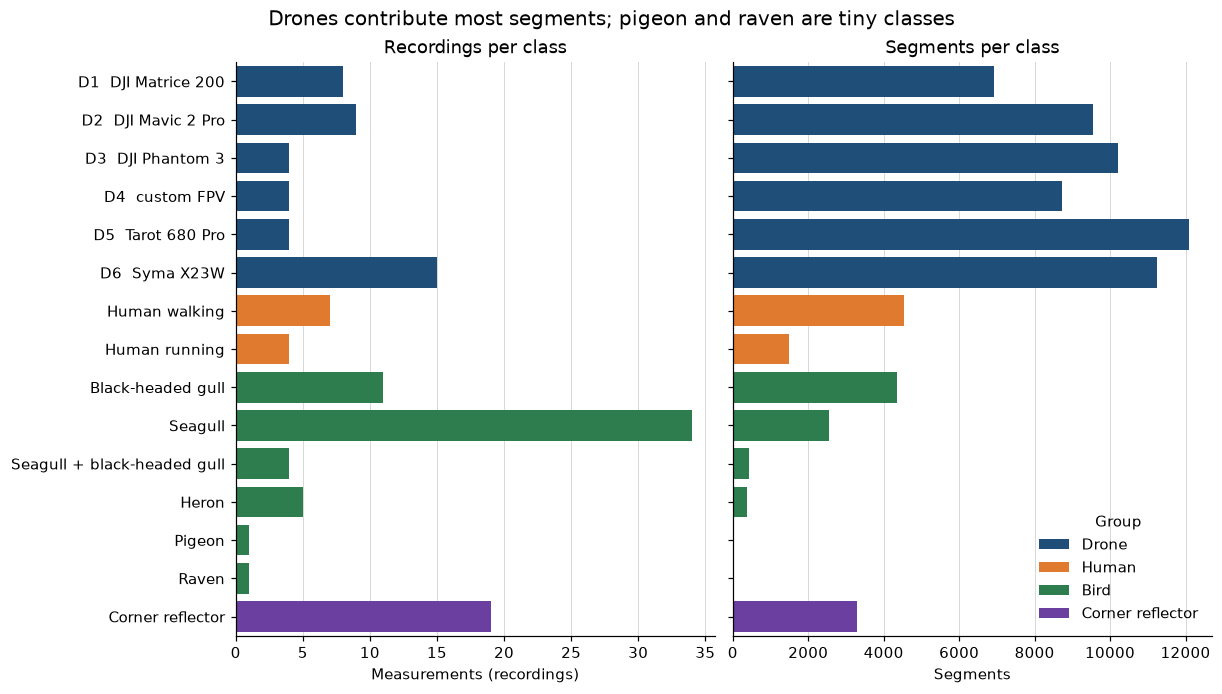

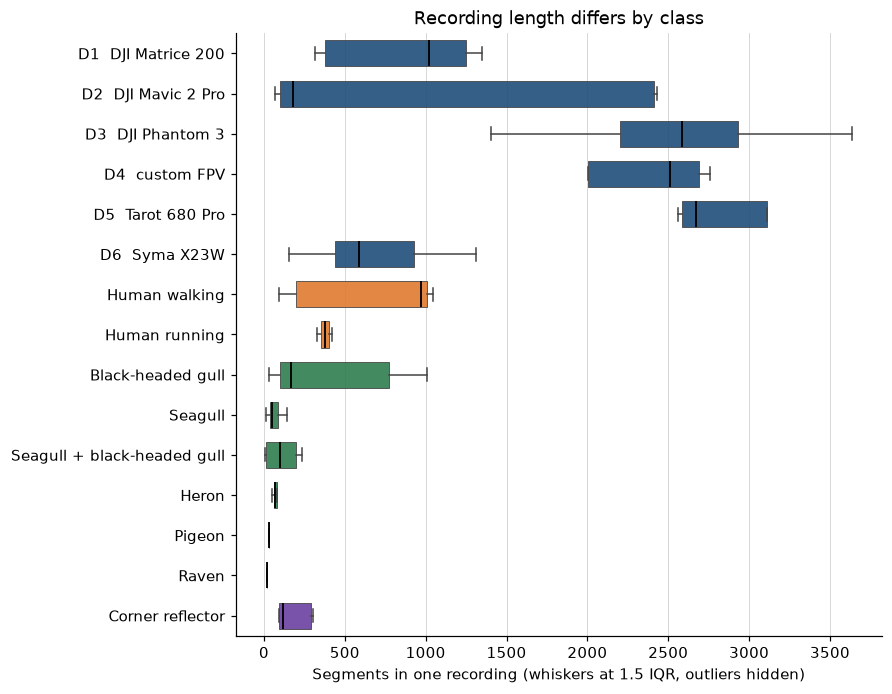

In [3]:
y = np.arange(len(CLASS_ORDER))
ylabels = [LABELS[lab] for lab in CLASS_ORDER]
colors = [GROUP_COLOR[GROUP[lab]] for lab in CLASS_ORDER]
n_recordings = seg.groupby("label").row.nunique().reindex(CLASS_ORDER)
n_segments = seg.groupby("label").size().reindex(CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), layout="constrained", sharey=True)
axes[0].barh(y, n_recordings.to_numpy(), color=colors)
axes[1].barh(y, n_segments.to_numpy(), color=colors)
for ax in axes:
    ax.set_yticks(y, ylabels)
    ax.set_ylim(len(CLASS_ORDER) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("Measurements (recordings)")
axes[1].set_xlabel("Segments")
axes[0].set_title("Recordings per class")
axes[1].set_title("Segments per class")
handles = [Patch(facecolor=GROUP_COLOR[g], label=GROUP_NAME[g]) for g in GROUP_ORDER]
axes[1].legend(handles=handles, title="Group", loc="lower right")
fig.suptitle("Drones contribute most segments; pigeon and raven are tiny classes", fontsize=13)
show(fig)

per_recording = seg.groupby(["label", "row"], sort=False).size().rename("n_segments").reset_index()
fig, ax = plt.subplots(figsize=(8, 6.2), layout="constrained")
order = list(reversed(CLASS_ORDER))
arrays = [per_recording.loc[per_recording.label == lab, "n_segments"].to_numpy() for lab in order]
bp = ax.boxplot(
    arrays,
    orientation="horizontal",
    tick_labels=[LABELS[lab] for lab in order],
    showfliers=False,
    patch_artist=True,
    widths=0.65,
    medianprops={"color": "black", "linewidth": 1.2},
    whiskerprops={"color": "#444444"},
    capprops={"color": "#444444"},
    boxprops={"linewidth": 0.6, "color": "#444444"},
)
for patch, lab in zip(bp["boxes"], order):
    patch.set_facecolor(GROUP_COLOR[GROUP[lab]])
    patch.set_alpha(0.9)
ax.set_xlabel("Segments in one recording (whiskers at 1.5 IQR, outliers hidden)")
ax.set_title("Recording length differs by class")
ax.grid(axis="y", visible=False)
show(fig)


## 4. Train, validation, and test

The readme’s fifth column is the split used by the dataset authors: 1 = train, 2 = validation, 3 = test. The question for later modeling is whether that flag holds out a whole recording, or whether pieces of the same recording appear in more than one split.


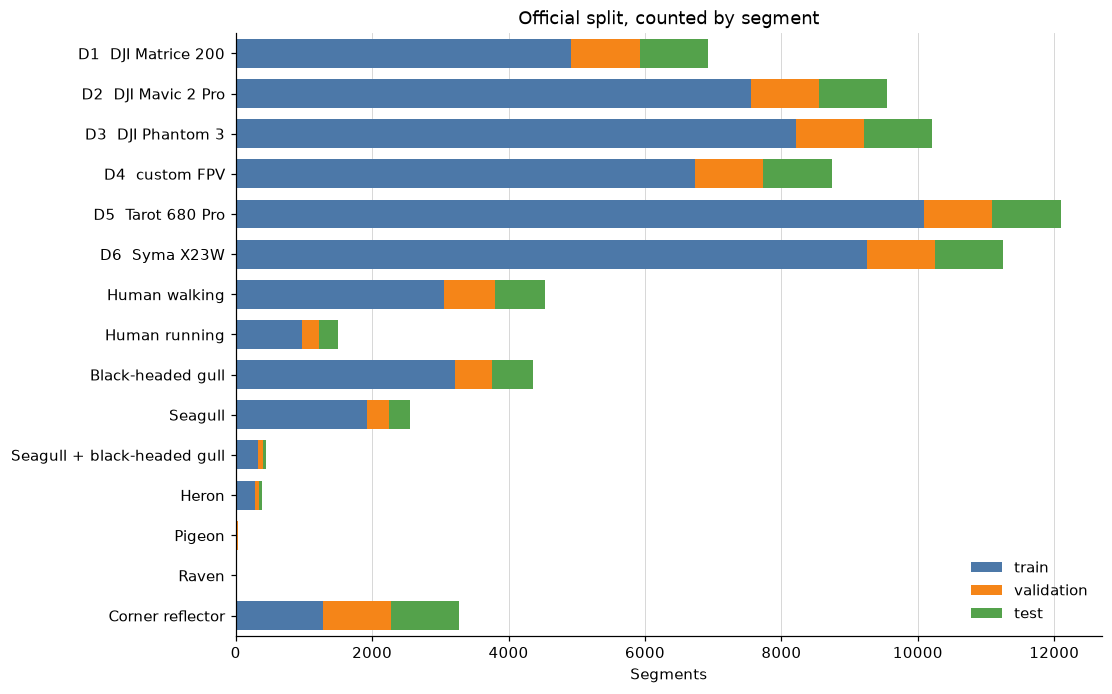

split_name,train,validation,test
Drone,46768,6000,6000
Human,4028,1000,1000
Bird,5792,1000,1000
Corner reflector,1280,1000,1000


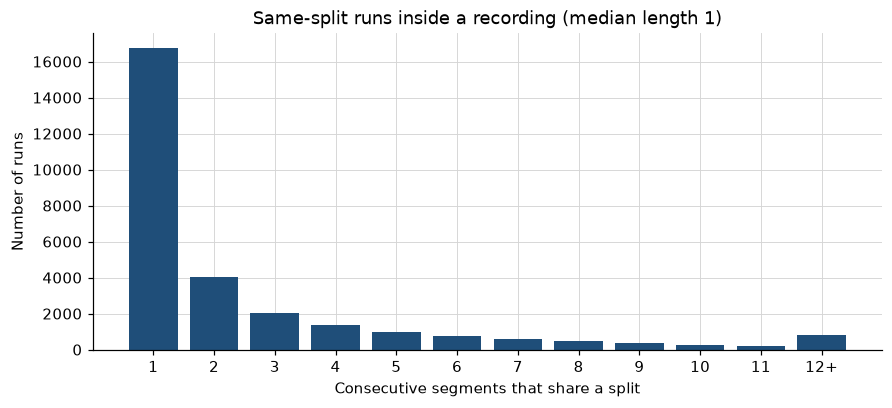

Recordings that appear in more than one split: 130 of 130
Recordings whose split time spans overlap: 129 of 130
Adjacent segments with different splits: 28,547 of 75,738 (37.7%)
Median run length 1, 90th percentile 6, max 43


In [4]:
split_counts = (
    pd.crosstab(seg["label"], seg["split_name"])
    .reindex(index=CLASS_ORDER, columns=["train", "validation", "test"])
    .fillna(0)
    .astype(int)
)
group_counts = (
    pd.crosstab(seg["group"], seg["split_name"])
    .reindex(index=GROUP_ORDER, columns=["train", "validation", "test"])
    .fillna(0)
    .astype(int)
)
group_counts.index = [GROUP_NAME[g] for g in group_counts.index]

fig, ax = plt.subplots(figsize=(10, 6.2), layout="constrained")
left = np.zeros(len(CLASS_ORDER))
for name in ["train", "validation", "test"]:
    vals = split_counts[name].to_numpy(dtype=float)
    ax.barh(y, vals, left=left, color=SPLIT_COLOR[name], label=name, height=0.72)
    left = left + vals
ax.set_yticks(y, ylabels)
ax.set_ylim(len(CLASS_ORDER) - 0.5, -0.5)
ax.set_xlabel("Segments")
ax.set_title("Official split, counted by segment")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
show(fig)

display(group_counts)

run_lengths = []
n_adjacent = 0
n_changes = 0
n_overlap = 0
n_multi = 0
for _, g in seg.groupby("row", sort=False):
    splits = g["split"].to_numpy()
    if g["split"].nunique() > 1:
        n_multi += 1
    if len(splits) > 1:
        n_adjacent += len(splits) - 1
        n_changes += int((splits[1:] != splits[:-1]).sum())
        cuts = np.flatnonzero(splits[1:] != splits[:-1]) + 1
        bounds = np.r_[0, cuts, len(splits)]
        run_lengths.append(np.diff(bounds))
    else:
        run_lengths.append(np.array([len(splits)]))
    spans = [(sg.time_s.min(), sg.time_s.max()) for _, sg in g.groupby("split", sort=False)]
    hit = False
    for i in range(len(spans)):
        for j in range(i + 1, len(spans)):
            if spans[i][0] <= spans[j][1] and spans[j][0] <= spans[i][1]:
                hit = True
    n_overlap += int(hit)
run_lengths = np.concatenate(run_lengths)

capped = np.clip(run_lengths, 1, 12)
levels, counts = np.unique(capped, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.bar(levels, counts, color="#1f4e79", width=0.8)
ax.set_xticks(levels, [str(v) if v < 12 else "12+" for v in levels])
ax.set_xlabel("Consecutive segments that share a split")
ax.set_ylabel("Number of runs")
ax.set_title(f"Same-split runs inside a recording (median length {np.median(run_lengths):.0f})")
show(fig)

print(f"Recordings that appear in more than one split: {n_multi} of {seg.row.nunique()}")
print(f"Recordings whose split time spans overlap: {n_overlap} of {seg.row.nunique()}")
print(f"Adjacent segments with different splits: {n_changes:,} of {n_adjacent:,} ({n_changes / n_adjacent:.1%})")
print(f"Median run length {np.median(run_lengths):.0f}, 90th percentile {np.percentile(run_lengths, 90):.0f}, max {run_lengths.max()}")


## 5. Range, time, and the scan edge

The range value is the range of the center cell, not of every cell. Time is seconds from the first sweep of that recording to the middle azimuth sample of the segment. The edge flag marks a target near the edge of the scan: the missing azimuth sweeps are filled with noise. The readme says this happens for 67 segments.

Segments are stored in time order. The readme says the gap between segments is about 100 ms, with holes when the target leaves the field of view or disappears into noise.


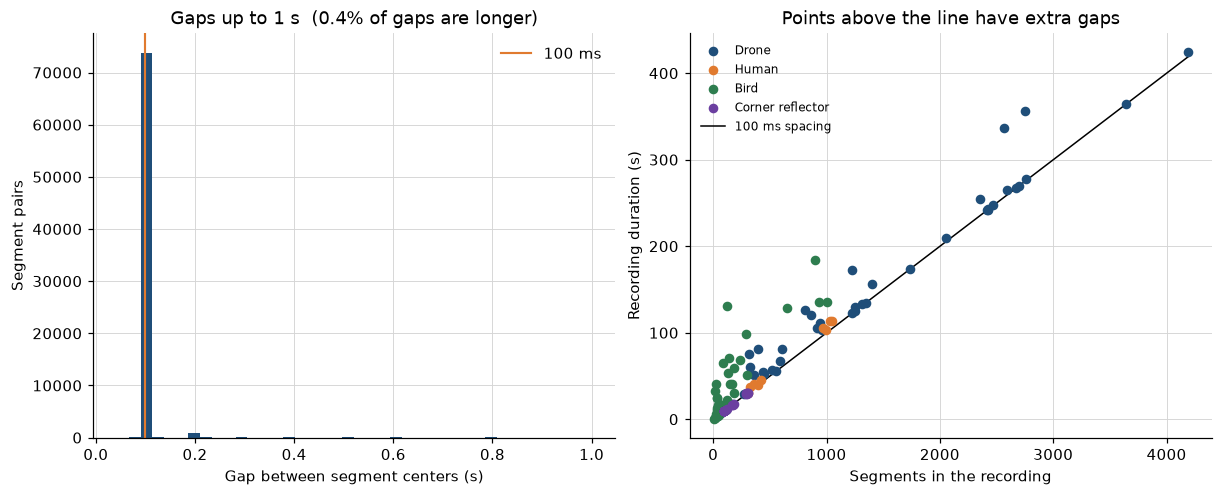

Median gap 100 ms   share of gaps between 80 and 120 ms 97.6%
Range 5.7–194.3 m


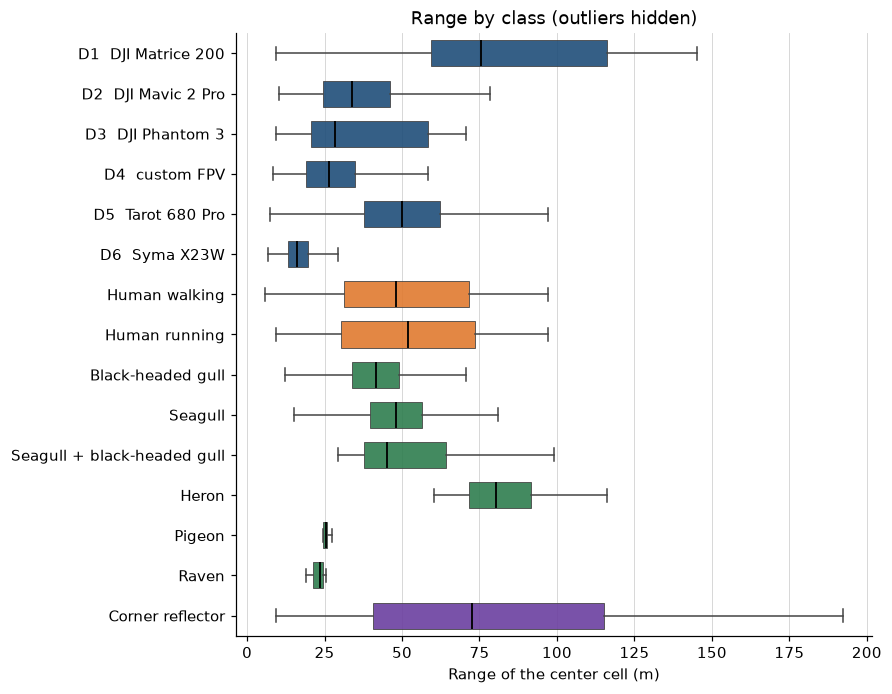

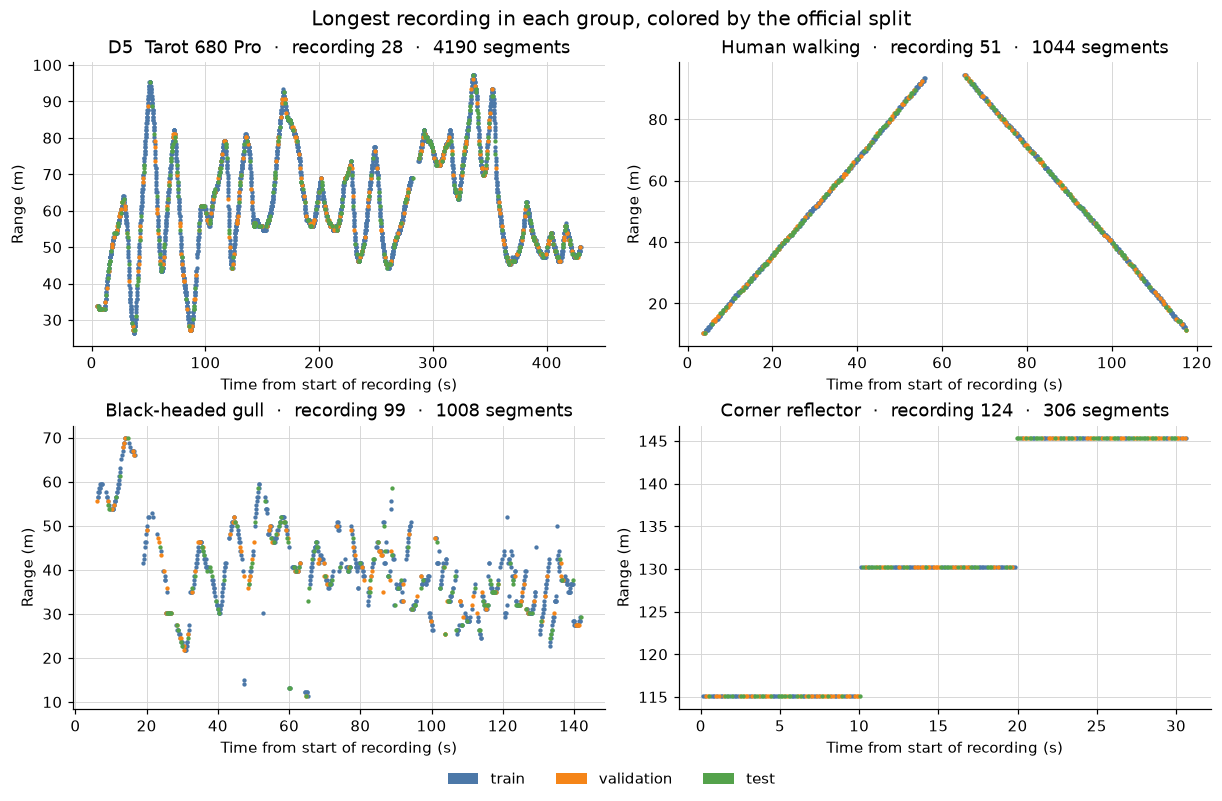

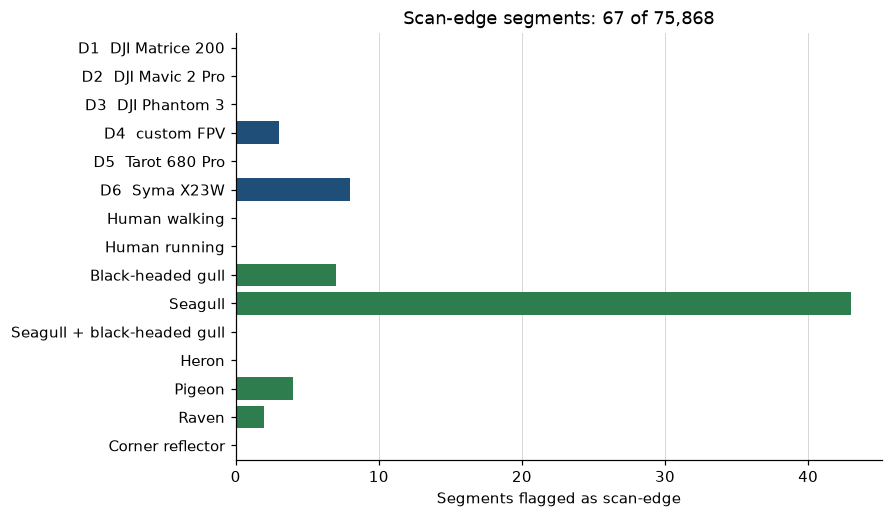

In [5]:
rec = seg.groupby("row", sort=False).agg(
    label=("label", "first"),
    group=("group", "first"),
    n_segments=("seg_idx", "size"),
    t0=("time_s", "min"),
    t1=("time_s", "max"),
    range_min=("range_m", "min"),
    range_max=("range_m", "max"),
)
rec["duration_s"] = rec["t1"] - rec["t0"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
gaps = seg["gap_s"].dropna()
axes[0].hist(gaps[gaps <= 1.0], bins=40, color="#1f4e79")
axes[0].axvline(0.1, color="#e07a2f", linewidth=1.4, label="100 ms")
axes[0].set_xlabel("Gap between segment centers (s)")
axes[0].set_ylabel("Segment pairs")
axes[0].set_title(f"Gaps up to 1 s  ({(gaps > 1).mean():.1%} of gaps are longer)")
axes[0].legend()

for gname in GROUP_ORDER:
    part = rec[rec.group == gname]
    axes[1].scatter(
        part.n_segments, part.duration_s,
        s=28, color=GROUP_COLOR[gname], label=GROUP_NAME[gname], zorder=3,
    )
x_ref = np.array([1, rec.n_segments.max()])
axes[1].plot(x_ref, (x_ref - 1) * 0.1, color="black", linewidth=1, label="100 ms spacing")
axes[1].set_xlabel("Segments in the recording")
axes[1].set_ylabel("Recording duration (s)")
axes[1].set_title("Points above the line have extra gaps")
axes[1].legend(fontsize=8)
show(fig)

print(f"Median gap {gaps.median() * 1e3:.0f} ms   share of gaps between 80 and 120 ms {(gaps.between(0.08, 0.12)).mean():.1%}")
print(f"Range {seg.range_m.min():.1f}–{seg.range_m.max():.1f} m")

fig, ax = plt.subplots(figsize=(8, 6.2), layout="constrained")
arrays = [seg.loc[seg.label == lab, "range_m"].to_numpy() for lab in order]
bp = ax.boxplot(
    arrays,
    orientation="horizontal",
    tick_labels=[LABELS[lab] for lab in order],
    showfliers=False,
    patch_artist=True,
    widths=0.65,
    medianprops={"color": "black", "linewidth": 1.2},
    whiskerprops={"color": "#444444"},
    capprops={"color": "#444444"},
    boxprops={"linewidth": 0.6, "color": "#444444"},
)
for patch, lab in zip(bp["boxes"], order):
    patch.set_facecolor(GROUP_COLOR[GROUP[lab]])
    patch.set_alpha(0.9)
ax.set_xlabel("Range of the center cell (m)")
ax.set_title("Range by class (outliers hidden)")
ax.grid(axis="y", visible=False)
show(fig)

# Longest recording in each group. Color is the official split.
picked = []
for gname in GROUP_ORDER:
    picked.append(rec[rec.group == gname].n_segments.idxmax())
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), layout="constrained", sharex=False, sharey=False)
for ax, row_id in zip(axes.ravel(), picked):
    g = seg[seg.row == row_id]
    for name in ["train", "validation", "test"]:
        part = g[g.split_name == name]
        if part.empty:
            continue
        ax.scatter(
            part.time_s, part.range_m,
            s=8, color=SPLIT_COLOR[name], label=name, rasterized=True, linewidths=0,
        )
    meta = rec.loc[row_id]
    ax.set_title(f"{LABELS[meta.label]}  ·  recording {row_id}  ·  {int(meta.n_segments)} segments")
    ax.set_xlabel("Time from start of recording (s)")
    ax.set_ylabel("Range (m)")
handles = [Patch(facecolor=SPLIT_COLOR[n], label=n) for n in ["train", "validation", "test"]]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
fig.suptitle("Longest recording in each group, colored by the official split", fontsize=13)
show(fig)

edge_counts = seg.loc[seg.edge == 1].groupby("label").size().reindex(CLASS_ORDER).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
ax.barh(y, edge_counts.to_numpy(), color=colors)
ax.set_yticks(y, ylabels)
ax.set_ylim(len(CLASS_ORDER) - 0.5, -0.5)
ax.set_xlabel("Segments flagged as scan-edge")
ax.set_title(f"Scan-edge segments: {int(seg.edge.sum())} of {len(seg):,}")
ax.grid(axis="y", visible=False)
show(fig)


## 6. Where the energy sits, and how wide the Doppler is

Two summaries of the complex segment:

- **Center-cell energy.** Share of the segment’s power that falls in range cell 2, the cell the range value refers to. If the crop is centered on the target, this share is high and the peak cell is cell 2.
- **Doppler power beyond ±1 m/s.** Hann-windowed FFT of the center cell across the 256 sweeps. Each segment is scaled to unit Doppler power, then the share outside ±1 m/s is kept. Velocity is FFT frequency × λ/2. Positive velocity means positive FFT frequency. The antenna is still moving during the 15 ms, so this is a short Doppler look mixed with a few degrees of scan, not a fixed-beam dwell.

The mean spectrum below averages those unit-power spectra, then scales the result to 0 dB at the peak.


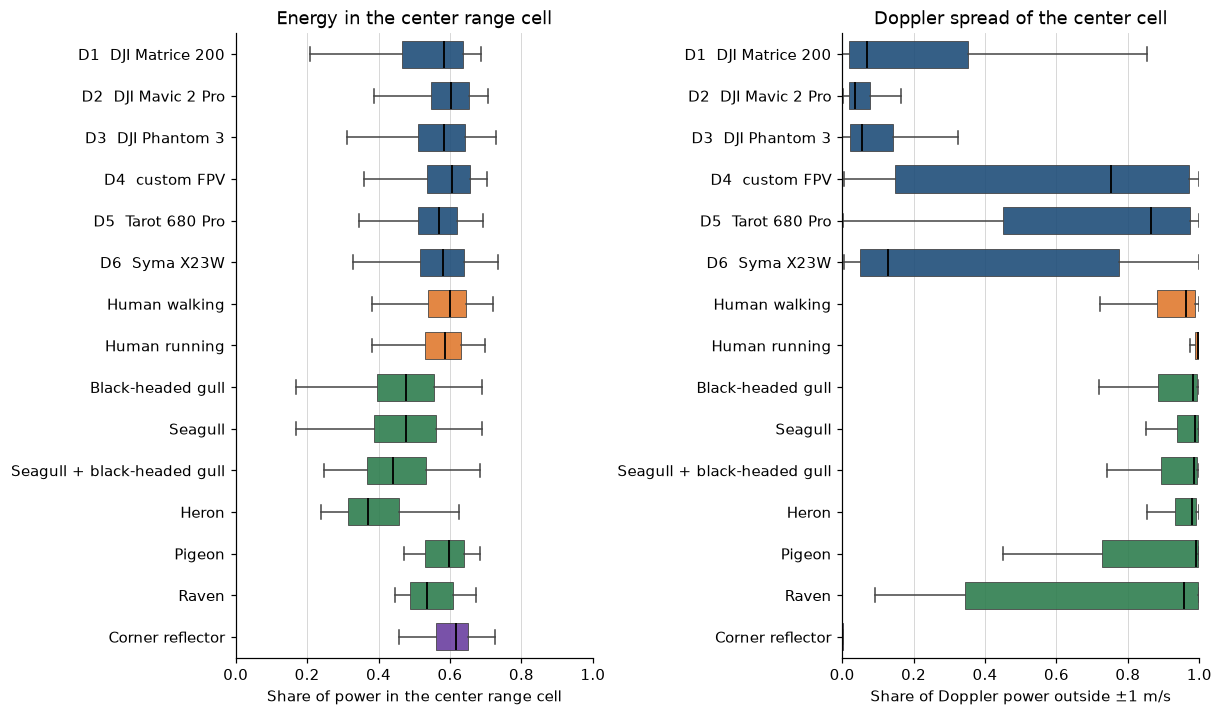

Peak range cell is the center cell in 99.0% of segments
Median center-cell energy share: 0.58


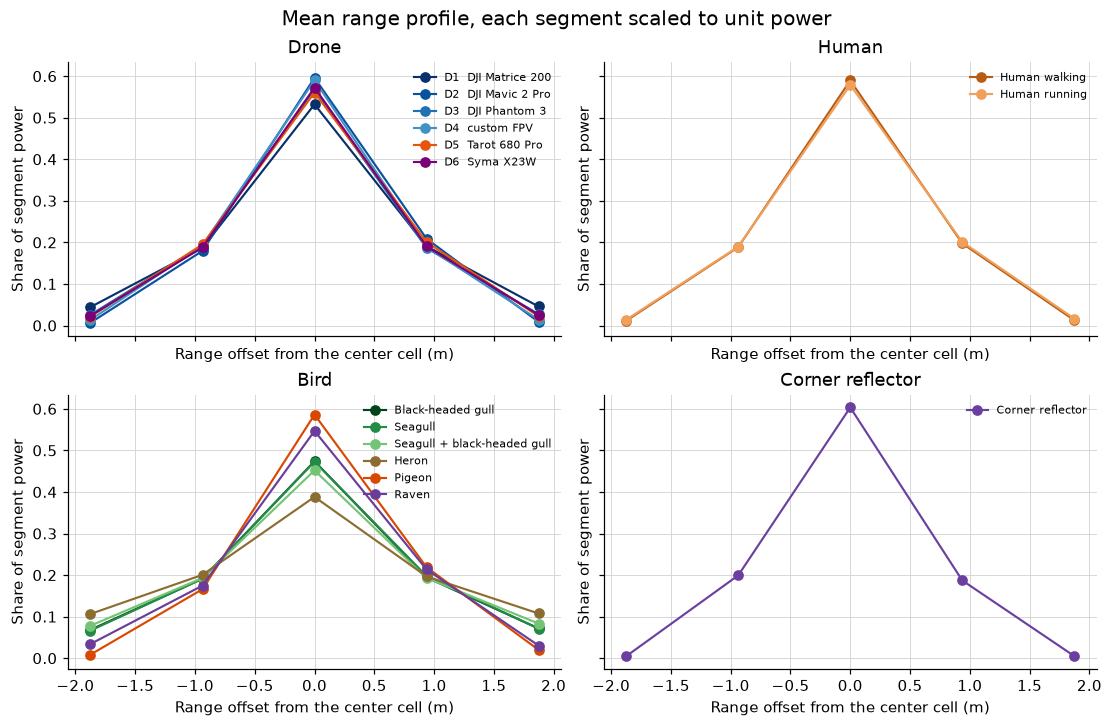

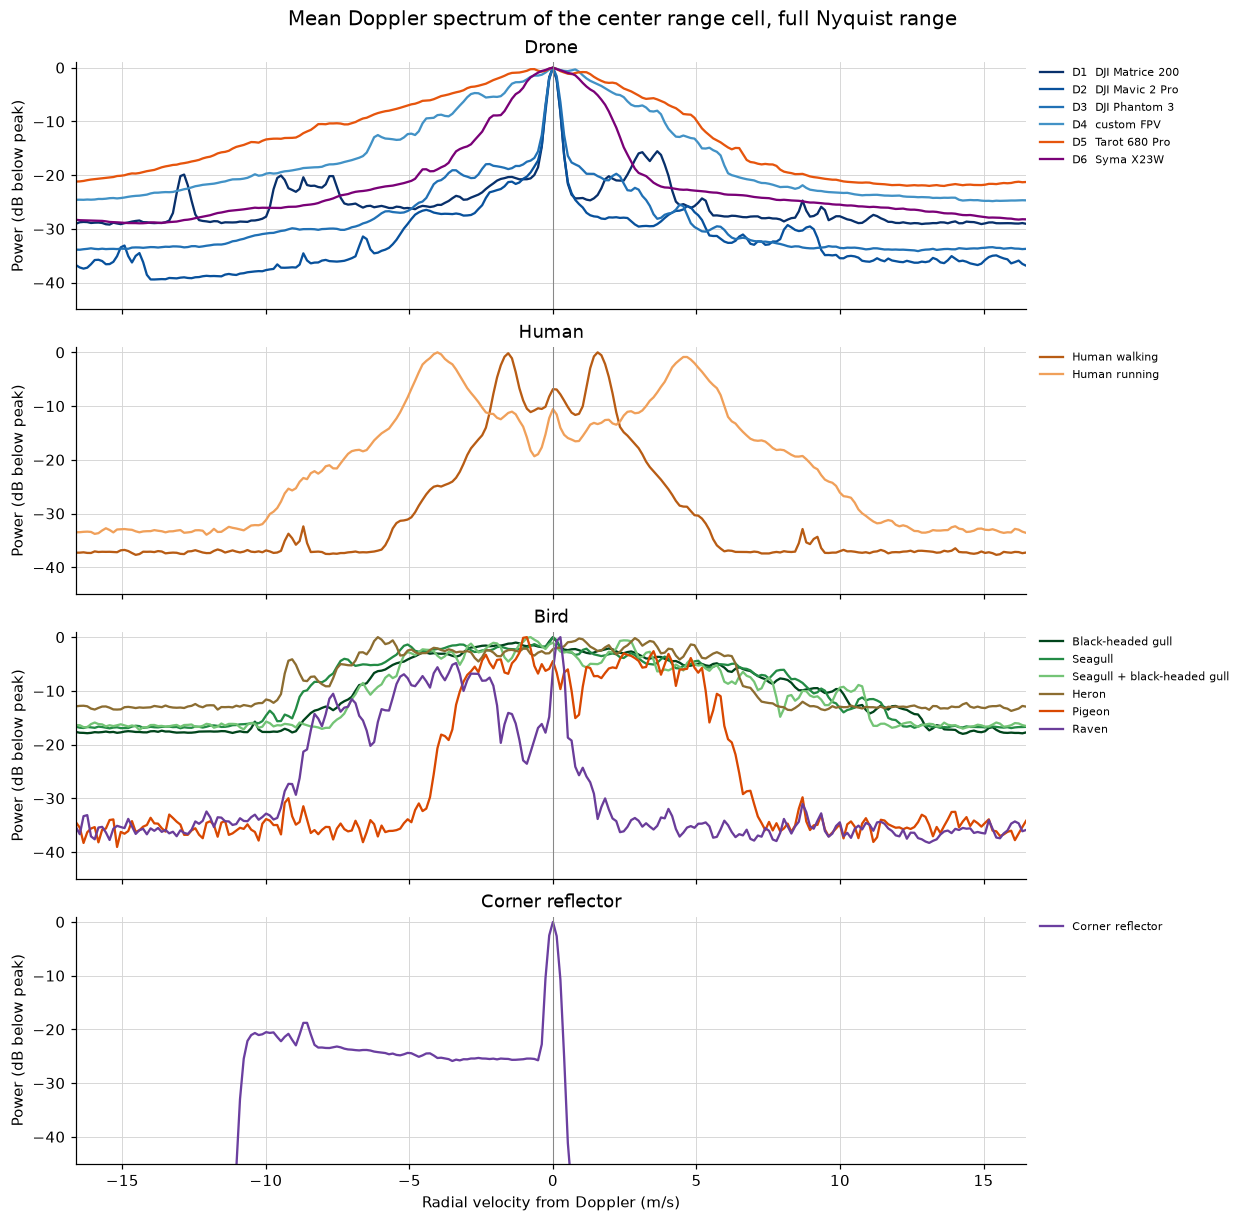

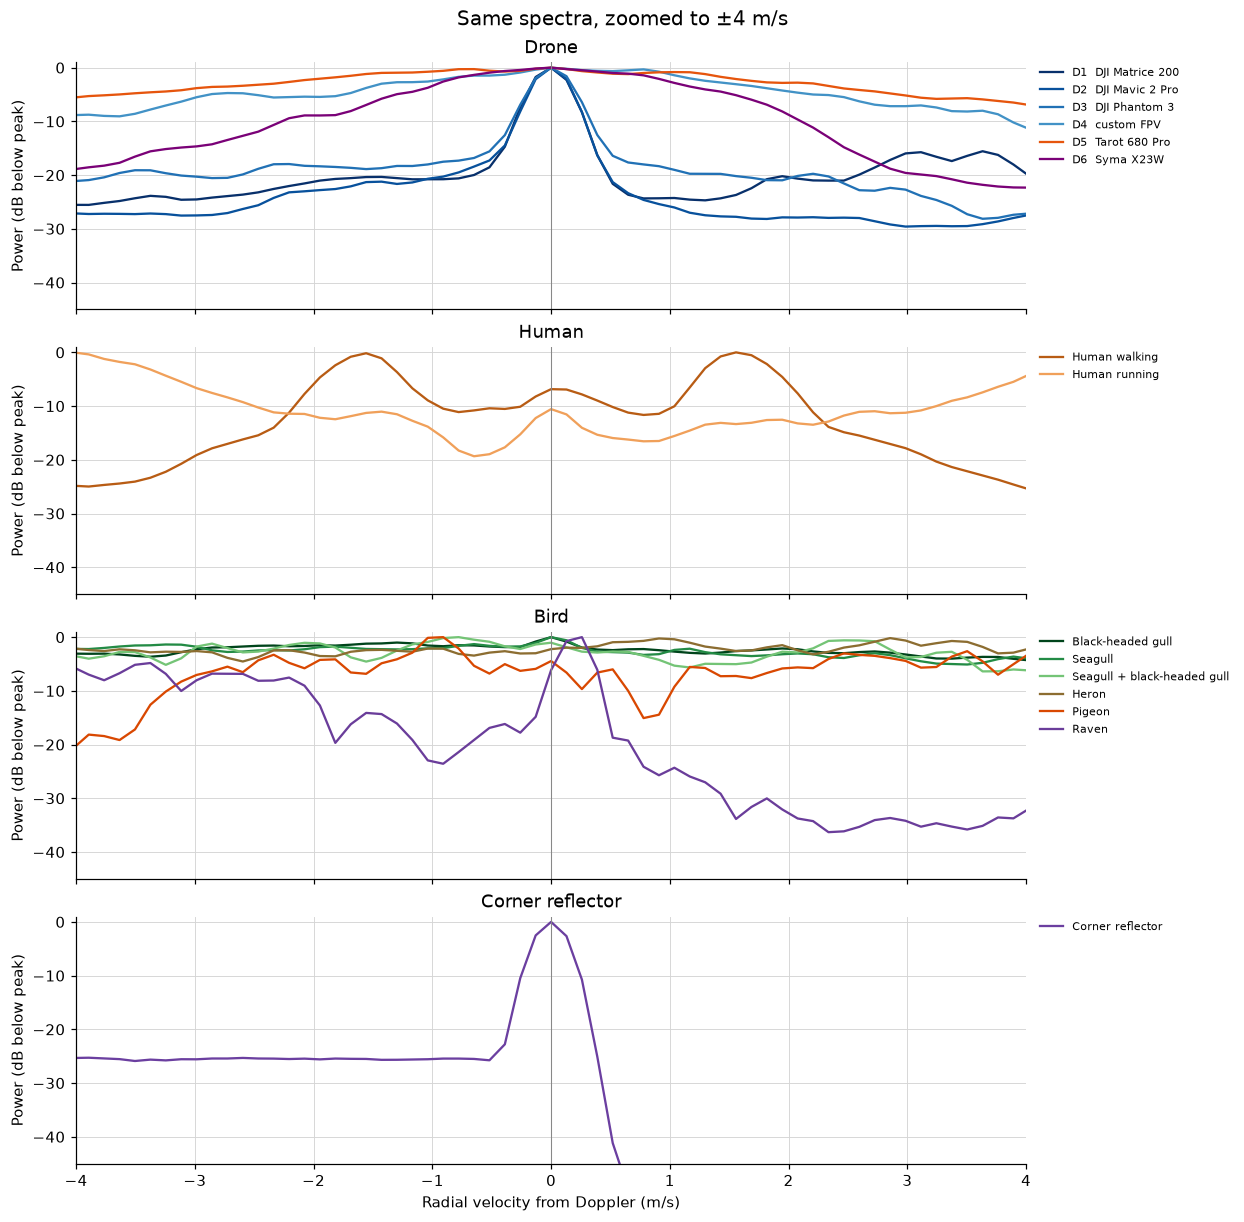

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.4), layout="constrained")
specs = [
    (axes[0], "center_frac", "Share of power in the center range cell"),
    (axes[1], "wide_frac", "Share of Doppler power outside ±1 m/s"),
]
for ax, column, xlabel in specs:
    arrays = [seg.loc[seg.label == lab, column].to_numpy() for lab in order]
    bp = ax.boxplot(
        arrays,
        orientation="horizontal",
        tick_labels=[LABELS[lab] for lab in order],
        showfliers=False,
        patch_artist=True,
        widths=0.65,
        medianprops={"color": "black", "linewidth": 1.2},
        whiskerprops={"color": "#444444"},
        capprops={"color": "#444444"},
        boxprops={"linewidth": 0.6, "color": "#444444"},
    )
    for patch, lab in zip(bp["boxes"], order):
        patch.set_facecolor(GROUP_COLOR[GROUP[lab]])
        patch.set_alpha(0.9)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
axes[0].set_title("Energy in the center range cell")
axes[1].set_title("Doppler spread of the center cell")
show(fig)

print(f"Peak range cell is the center cell in {(seg.peak_bin == 2).mean():.1%} of segments")
print(f"Median center-cell energy share: {seg.center_frac.median():.2f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), layout="constrained", sharex=True, sharey=True)
offsets = (np.arange(N_RANGE) - 2) * RANGE_BIN_M
for ax, gname in zip(axes.ravel(), GROUP_ORDER):
    for lab in CLASS_ORDER:
        if GROUP[lab] != gname:
            continue
        profile = range_acc[lab] / n_acc[lab]
        ax.plot(offsets, profile, marker="o", color=CLASS_COLOR[lab], label=LABELS[lab], linewidth=1.4)
    ax.set_title(GROUP_NAME[gname])
    ax.set_xlabel("Range offset from the center cell (m)")
    ax.set_ylabel("Share of segment power")
    ax.legend(fontsize=7)
fig.suptitle("Mean range profile, each segment scaled to unit power", fontsize=13)
show(fig)

def mean_spectrum_db(lab):
    spectrum = spec_acc[lab] / n_acc[lab]
    spectrum = spectrum / spectrum.max()
    return 10 * np.log10(np.maximum(spectrum, 1e-12))

def plot_spectra(xlim, ylim, title):
    fig, axes = plt.subplots(4, 1, figsize=(11.2, 11), layout="constrained", sharex=True, sharey=True)
    for ax, gname in zip(axes, GROUP_ORDER):
        for lab in CLASS_ORDER:
            if GROUP[lab] != gname:
                continue
            ax.plot(V_AXIS, mean_spectrum_db(lab), color=CLASS_COLOR[lab], label=LABELS[lab], linewidth=1.5)
        ax.axvline(0, color="#888888", linewidth=0.7)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_ylabel("Power (dB below peak)")
        ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1.0), borderaxespad=0)
        ax.set_title(GROUP_NAME[gname])
    axes[-1].set_xlabel("Radial velocity from Doppler (m/s)")
    fig.suptitle(title, fontsize=13)
    show(fig)

plot_spectra(
    (float(V_AXIS.min()), float(V_AXIS.max())),
    (-45, 1),
    "Mean Doppler spectrum of the center range cell, full Nyquist range",
)
plot_spectra(
    (-4, 4),
    (-45, 1),
    "Same spectra, zoomed to ±4 m/s",
)


## 7. Does the Doppler centroid follow the range rate?

Range rate is the change in reported range divided by the gap between segments, kept only for gaps of 50–200 ms (the regular cadence, not the long dropouts). The Doppler centroid is the first moment of that segment’s windowed spectrum. Agreement would mean the 15 ms look is mostly bulk radial motion. Disagreement means rotation, flapping, scan motion, or a sign convention is carrying the spectrum.


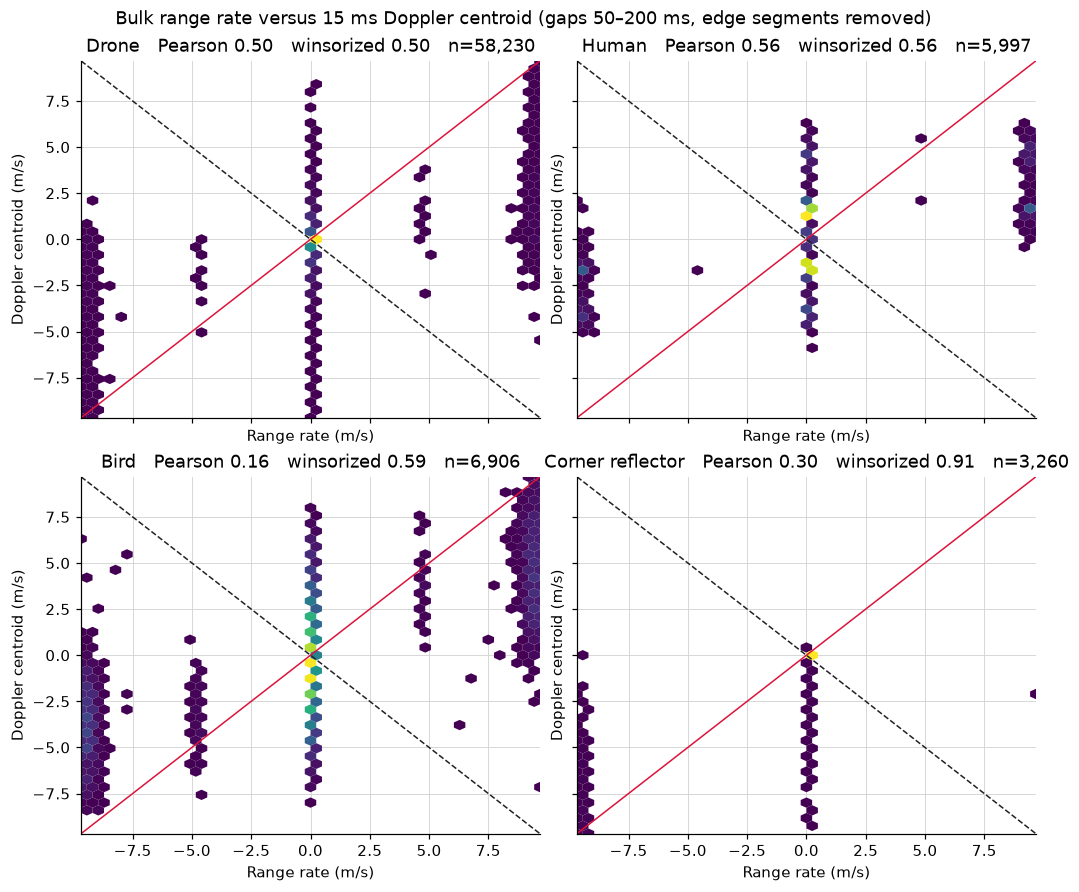

Plotted window is the central 99% of |velocity|, capped at ±9.7 m/s
Segments in this comparison: 74,393 of 75,868


In [7]:
motion = seg[seg.gap_s.between(0.05, 0.20) & (seg.edge == 0)].dropna(
    subset=["range_rate_m_s", "v_centroid_m_s"]
)
fig, axes = plt.subplots(2, 2, figsize=(9.4, 8), layout="constrained", sharex=True, sharey=True)
span = np.nanpercentile(
    np.abs(np.concatenate([motion.range_rate_m_s.to_numpy(), motion.v_centroid_m_s.to_numpy()])),
    99,
)
span = float(np.clip(span, 1, 25))
motion_r = {}
for ax, gname in zip(axes.ravel(), GROUP_ORDER):
    part = motion[motion.group == gname]
    ax.hexbin(
        part.range_rate_m_s, part.v_centroid_m_s,
        gridsize=40, extent=(-span, span, -span, span),
        cmap="viridis", mincnt=1, linewidths=0,
    )
    ax.plot([-span, span], [-span, span], color="crimson", linewidth=1, label="same sign")
    ax.plot([-span, span], [span, -span], color="#222222", linewidth=1, linestyle="--", label="opposite sign")
    r_raw = pearson(part.range_rate_m_s, part.v_centroid_m_s)
    r_win = winsorized_pearson(part.range_rate_m_s, part.v_centroid_m_s)
    motion_r[gname] = (r_raw, r_win, len(part))
    ax.set_title(f"{GROUP_NAME[gname]}   Pearson {r_raw:.2f}   winsorized {r_win:.2f}   n={len(part):,}")
    ax.set_xlim(-span, span)
    ax.set_ylim(-span, span)
    ax.set_xlabel("Range rate (m/s)")
    ax.set_ylabel("Doppler centroid (m/s)")
fig.suptitle("Bulk range rate versus 15 ms Doppler centroid (gaps 50–200 ms, edge segments removed)", fontsize=12)
show(fig)
print(f"Plotted window is the central 99% of |velocity|, capped at ±{span:.1f} m/s")
print(f"Segments in this comparison: {len(motion):,} of {len(seg):,}")


## 8. What one segment looks like

For each class, the segment shown is a non-edge segment whose mean power is closest to that class’s median. The trace is the magnitude of the center range cell across the 15 ms. The image is the whole 5 × 256 crop, in dB relative to that segment’s peak. Color scales on the traces are independent because received power depends on range and radar cross section. The images share one color scale.

The arch that peaks near the middle of the 15 ms is the antenna beam sweeping across the target. It is there for the corner reflector too, and that return is otherwise smooth. Ripple on the arch is the target, not the scan.


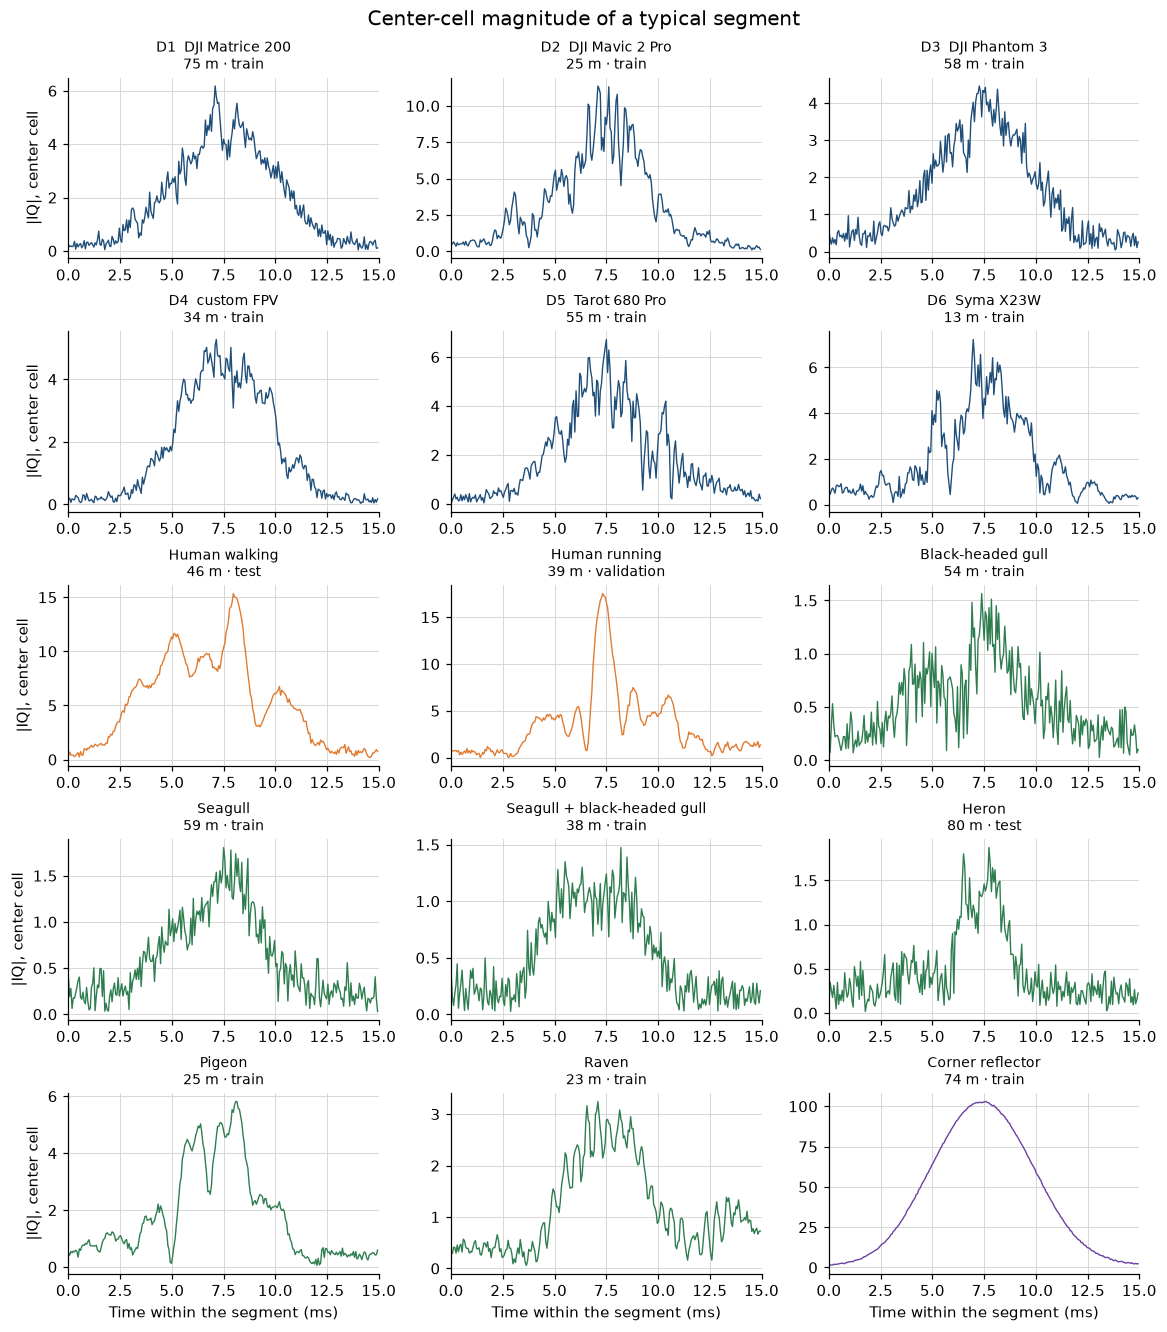

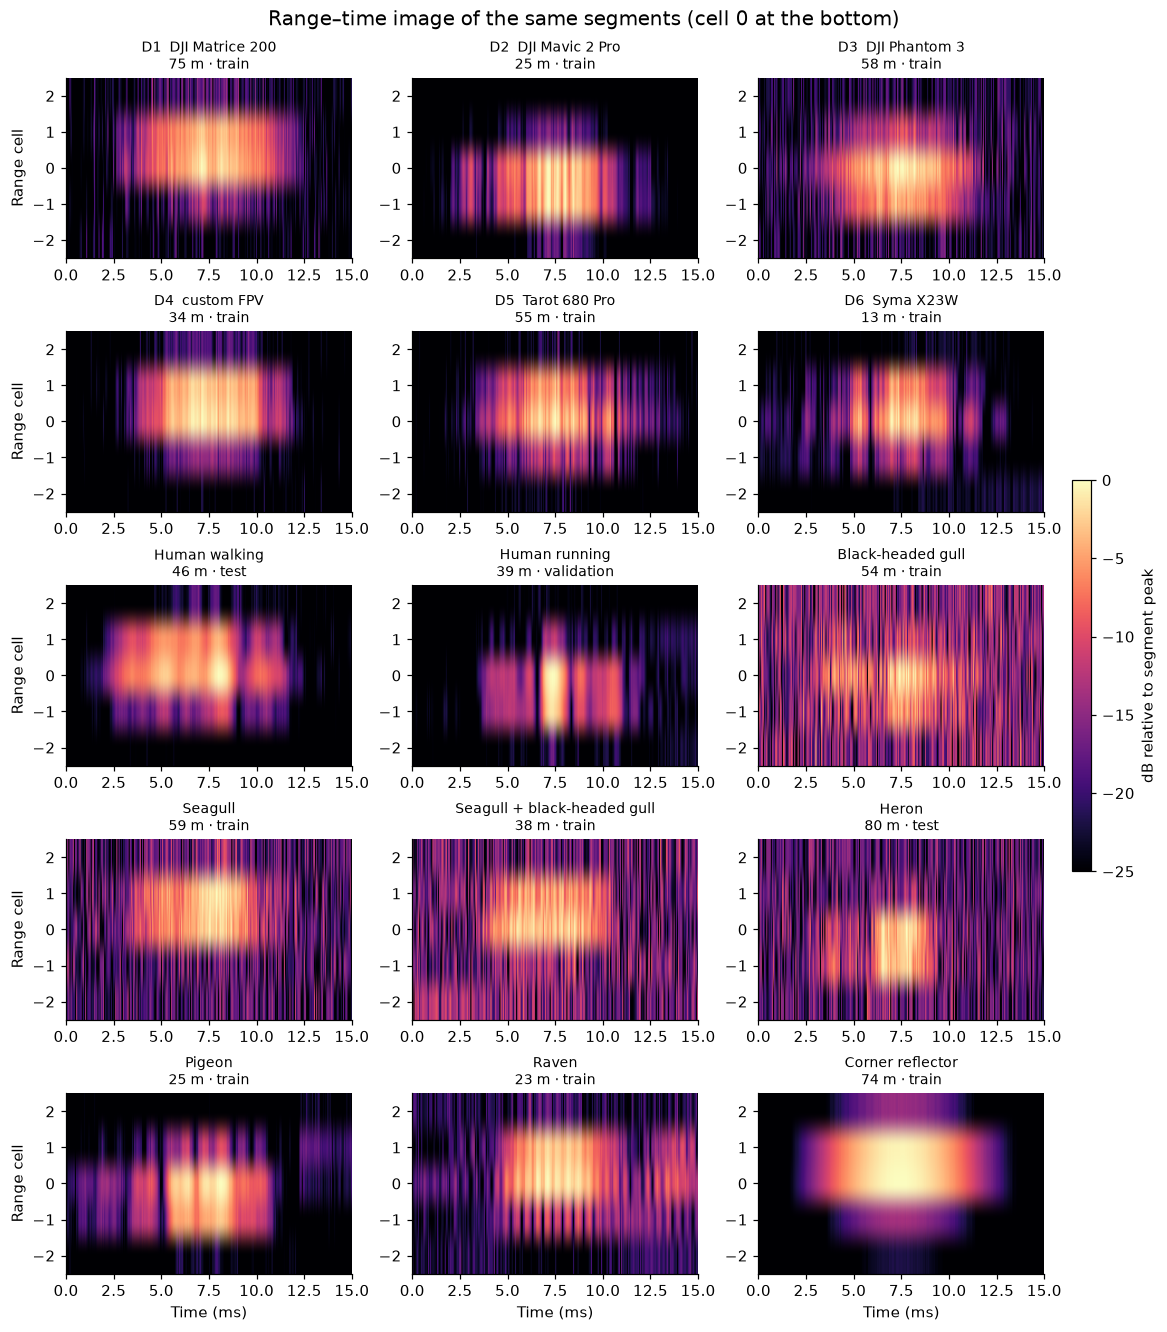

In [8]:
chosen = {}
for lab in CLASS_ORDER:
    pool = seg[(seg.label == lab) & (seg.edge == 0)]
    if pool.empty:
        pool = seg[seg.label == lab]
    median_power = pool.mean_power.median()
    pick = (pool.mean_power - median_power).abs().idxmin()
    chosen[lab] = seg.loc[pick]

fig, axes = plt.subplots(5, 3, figsize=(10.5, 12), layout="constrained")
t_ms = np.arange(N_AZ) * DT_S * 1e3
for ax, lab in zip(axes.ravel(), CLASS_ORDER):
    rec_row = chosen[lab]
    column = raw[int(rec_row.row), 1][:, int(rec_row.seg_idx)]
    ax.plot(t_ms, np.abs(column[2 * N_AZ:3 * N_AZ]), color=GROUP_COLOR[GROUP[lab]], linewidth=0.9)
    ax.set_title(f"{LABELS[lab]}\n{rec_row.range_m:.0f} m · {rec_row.split_name}", fontsize=9)
    ax.set_xlim(0, 15)
    ax.grid(True)
for ax in axes[-1]:
    ax.set_xlabel("Time within the segment (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("|IQ|, center cell")
fig.suptitle("Center-cell magnitude of a typical segment", fontsize=13)
show(fig)

fig, axes = plt.subplots(5, 3, figsize=(10.5, 12), layout="constrained")
image = None
for ax, lab in zip(axes.ravel(), CLASS_ORDER):
    rec_row = chosen[lab]
    column = raw[int(rec_row.row), 1][:, int(rec_row.seg_idx)]
    magnitude = np.abs(column).reshape(N_RANGE, N_AZ)
    db = 20 * np.log10(magnitude / magnitude.max() + 1e-12)
    image = ax.imshow(
        db, origin="lower", aspect="auto",
        extent=(0, 15, -2.5, 2.5), vmin=-25, vmax=0, cmap="magma",
    )
    ax.set_yticks([-2, -1, 0, 1, 2])
    ax.set_title(f"{LABELS[lab]}\n{rec_row.range_m:.0f} m · {rec_row.split_name}", fontsize=9)
    ax.grid(False)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Range cell")
fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.02, pad=0.01, label="dB relative to segment peak")
fig.suptitle("Range–time image of the same segments (cell 0 at the bottom)", fontsize=13)
show(fig)


## 9. Summary


In [9]:
rows = []
for lab in CLASS_ORDER:
    part = seg[seg.label == lab]
    rows.append({
        "Class": LABELS[lab],
        "Group": GROUP_NAME[GROUP[lab]],
        "Recordings": int(part.row.nunique()),
        "Segments": int(len(part)),
        "Train": int((part.split == 1).sum()),
        "Validation": int((part.split == 2).sum()),
        "Test": int((part.split == 3).sum()),
        "Edge": int(part.edge.sum()),
        "Median range (m)": part.range_m.median(),
        "Median center-cell power": part.center_frac.median(),
        "Median Doppler share beyond ±1 m/s": part.wide_frac.median(),
        "Median Doppler RMS (m/s)": part.v_rms_m_s.median(),
    })
summary = pd.DataFrame(rows)
display(
    summary.style.format({
        "Segments": "{:,}",
        "Train": "{:,}",
        "Validation": "{:,}",
        "Test": "{:,}",
        "Median range (m)": "{:.0f}",
        "Median center-cell power": "{:.2f}",
        "Median Doppler share beyond ±1 m/s": "{:.2f}",
        "Median Doppler RMS (m/s)": "{:.2f}",
    }).hide(axis="index")
)

largest = summary.loc[summary["Segments"].idxmax()]
smallest = summary.loc[summary["Segments"].idxmin()]
by_class = summary.set_index("Class")
share_col = "Median Doppler share beyond ±1 m/s"
rms_col = "Median Doppler RMS (m/s)"

def share(lab):
    return float(by_class.loc[LABELS[lab], share_col])

def rms(lab):
    return float(by_class.loc[LABELS[lab], rms_col])

text = f'''
The file matches the readme: **{raw.shape[0]} measurements**, **{len(seg):,} segments**, **{int(seg.edge.sum())} scan-edge segments**, and no non-finite IQ samples. Each segment is a complex vector of length 1,280, stored down a column of the complex matrix.

**Class balance.** `{largest["Class"].strip()}` has the most segments ({int(largest["Segments"]):,}). `{smallest["Class"].strip()}` has the fewest ({int(smallest["Segments"]):,}). Drones are { (seg.group == "drone").mean():.0%} of all segments. Pigeon and raven are single recordings with a few dozen segments, so any per-class score on those two labels will be unstable.

**The official split does not hold out recordings.** {n_multi} of {seg.row.nunique()} recordings contribute segments to more than one of train, validation, and test, and {n_overlap} have overlapping time spans across splits. The median run of consecutive segments with the same split is {np.median(run_lengths):.0f}. {n_changes / n_adjacent:.0%} of neighboring segments (about 100 ms apart, same target) are assigned to different splits. Validation and test counts are capped at 1,000 segments for each drone and for the corner reflector; birds and humans are smaller. A model can therefore see the same flight in the training set and the test set. A split that keeps each recording in one set would be a stricter test of generalization.

**Geometry.** Reported range runs from {seg.range_m.min():.0f} m to {seg.range_m.max():.0f} m. The median gap between segment centers is {gaps.median() * 1e3:.0f} ms, and {(gaps.between(0.08, 0.12)).mean():.0%} of gaps fall between 80 and 120 ms. The remaining gaps are the dropouts described in the readme. The peak range cell is the center cell in {(seg.peak_bin == 2).mean():.0%} of segments, and the median share of power in that cell is {seg.center_frac.median():.2f}. The five range bins are a tight crop around the detection, so the range profile separates classes only weakly.

**Doppler shape separates targets that the five range bins do not.** The median share of Doppler power outside ±1 m/s is {share("CR"):.2f} for the corner reflector, {share("D2"):.2f}–{share("D1"):.2f} for the three DJI drones, {share("D6"):.2f} for the Syma, {share("D4"):.2f} for the custom FPV, and {share("D5"):.2f} for the Tarot. Walking is {share("human_walk"):.2f} and running is {share("human_run"):.2f}; birds as a group are {seg.loc[seg.group == "bird", "wide_frac"].median():.2f}. That share saturates, so the spectrum shape is the useful part. The reflector is a narrow tone. D1–D3 keep a narrow core and a low floor. D4 and D5 stay high across several metres per second. Walking has a narrow core plus lobes near ±2 m/s (RMS {rms("human_walk"):.2f} m/s); running is a wider hump (RMS {rms("human_run"):.2f} m/s). Pigeon ({int((seg.label == "pigeon").sum())} segments) and raven ({int((seg.label == "raven").sum())} segments) are too small to treat as stable classes. Nyquist velocity is ±{V_AXIS.max():.0f} m/s.

**The arch on a single segment is the antenna beam.** Center-cell magnitude rises and falls once over the 15 ms, including on the corner reflector, whose return is otherwise smooth. Ripple on that arch is the target.

**Range rate does not equal the Doppler centroid.** Pearson r is {motion_r["drone"][0]:.2f} for drones, {motion_r["human"][0]:.2f} for humans, {motion_r["bird"][0]:.2f} for birds, and {motion_r["reflector"][0]:.2f} for the reflector (winsorized: {motion_r["drone"][1]:.2f}, {motion_r["human"][1]:.2f}, {motion_r["bird"][1]:.2f}, {motion_r["reflector"][1]:.2f}). The points stack in vertical bands, including at 0 m/s and near ±5 and ±10 m/s, instead of along the diagonal. One range cell is {RANGE_BIN_M:.2f} m, so a one-cell step is {RANGE_BIN_M / 0.1:.1f} m/s over a 100 ms gap and {RANGE_BIN_M / 0.2:.1f} m/s over a 200 ms gap. Those bands are the range track stepping by a resolution cell.

**Edge flags** are rare ({int(seg.edge.sum())} segments) and concentrated in a few classes, mostly seagulls. They are real samples, but the missing sweeps are noise fills.
'''
display(Markdown(textwrap.dedent(text).strip()))


Class,Group,Recordings,Segments,Train,Validation,Test,Edge,Median range (m),Median center-cell power,Median Doppler share beyond ±1 m/s,Median Doppler RMS (m/s)
D1 DJI Matrice 200,Drone,8,"6,921","4,921","1,000","1,000",0,75,0.58,0.07,1.19
D2 DJI Mavic 2 Pro,Drone,9,"9,555","7,555","1,000","1,000",0,34,0.60,0.04,0.87
D3 DJI Phantom 3,Drone,4,"10,212","8,212","1,000","1,000",0,28,0.58,0.05,1.31
D4 custom FPV,Drone,4,"8,735","6,735","1,000","1,000",3,26,0.60,0.75,1.89
D5 Tarot 680 Pro,Drone,4,"12,093","10,093","1,000","1,000",0,50,0.57,0.87,2.50
D6 Syma X23W,Drone,15,"11,252","9,252","1,000","1,000",8,16,0.58,0.13,1.44
Human walking,Human,7,"4,529","3,056",750,723,0,48,0.60,0.96,0.49
Human running,Human,4,"1,499",972,250,277,0,52,0.58,1.00,0.92
Black-headed gull,Bird,11,"4,364","3,214",550,600,7,42,0.48,0.98,2.29
Seagull,Bird,34,"2,550","1,919",326,305,43,48,0.48,0.99,2.41


The file matches the readme: **130 measurements**, **75,868 segments**, **67 scan-edge segments**, and no non-finite IQ samples. Each segment is a complex vector of length 1,280, stored down a column of the complex matrix.

**Class balance.** `D5  Tarot 680 Pro` has the most segments (12,093). `Raven` has the fewest (19). Drones are 77% of all segments. Pigeon and raven are single recordings with a few dozen segments, so any per-class score on those two labels will be unstable.

**The official split does not hold out recordings.** 130 of 130 recordings contribute segments to more than one of train, validation, and test, and 129 have overlapping time spans across splits. The median run of consecutive segments with the same split is 1. 38% of neighboring segments (about 100 ms apart, same target) are assigned to different splits. Validation and test counts are capped at 1,000 segments for each drone and for the corner reflector; birds and humans are smaller. A model can therefore see the same flight in the training set and the test set. A split that keeps each recording in one set would be a stricter test of generalization.

**Geometry.** Reported range runs from 6 m to 194 m. The median gap between segment centers is 100 ms, and 98% of gaps fall between 80 and 120 ms. The remaining gaps are the dropouts described in the readme. The peak range cell is the center cell in 99% of segments, and the median share of power in that cell is 0.58. The five range bins are a tight crop around the detection, so the range profile separates classes only weakly.

**Doppler shape separates targets that the five range bins do not.** The median share of Doppler power outside ±1 m/s is 0.00 for the corner reflector, 0.04–0.07 for the three DJI drones, 0.13 for the Syma, 0.75 for the custom FPV, and 0.87 for the Tarot. Walking is 0.96 and running is 1.00; birds as a group are 0.98. That share saturates, so the spectrum shape is the useful part. The reflector is a narrow tone. D1–D3 keep a narrow core and a low floor. D4 and D5 stay high across several metres per second. Walking has a narrow core plus lobes near ±2 m/s (RMS 0.49 m/s); running is a wider hump (RMS 0.92 m/s). Pigeon (32 segments) and raven (19 segments) are too small to treat as stable classes. Nyquist velocity is ±16 m/s.

**The arch on a single segment is the antenna beam.** Center-cell magnitude rises and falls once over the 15 ms, including on the corner reflector, whose return is otherwise smooth. Ripple on that arch is the target.

**Range rate does not equal the Doppler centroid.** Pearson r is 0.50 for drones, 0.56 for humans, 0.16 for birds, and 0.30 for the reflector (winsorized: 0.50, 0.56, 0.59, 0.91). The points stack in vertical bands, including at 0 m/s and near ±5 and ±10 m/s, instead of along the diagonal. One range cell is 0.94 m, so a one-cell step is 9.4 m/s over a 100 ms gap and 4.7 m/s over a 200 ms gap. Those bands are the range track stepping by a resolution cell.

**Edge flags** are rare (67 segments) and concentrated in a few classes, mostly seagulls. They are real samples, but the missing sweeps are noise fills.